### Traffic Accidents in the US
## Jocelyn Rivera
# Introduction 

My research question is, “Is there a significant difference in the average severity of traffic accidents during the day and at night in the United States?” I chose this topic because traffic accidents are something that influences people every day, and I wanted to find out if accidents that happen during the day and at night have different influence on traffic. My goal is to compare the average severity ratings of these two groups.

The dataset I used was the US Accidents (2016-2023) dataset by Sobhan Moosavi on Kaggle. The data set contains about 7.7 million accident records from 49 states. I decided to work on two variables. `Sunrise_Sunset` which tells if the accident happened during day or night and `Severity` which tells how much the accident affects traffic on a scale from 1 to 4. I also checked for missing values and removed records without daytime or nighttime information before conducting my analysis.

### Data Analysis and Statistical Inference

I took the columns `Sunrise_Sunset` and `Severity` from the US Accidents dataset to compare traffic accidents during the day and night for my analysis. First, I checked the data set for missing values and saw that there were 23,246 records missing a day or night value. I removed these records because I needed to know if each incident was during the day or at night. Once the data was cleaned, I was left with 7,705,148 accident records. Of them, 5,334,553 were during the day and 2,370,595 at night. Next, I averaged the severity rating for each group. The average for the day was 2.2094 while the average for the night was 2.2191. Lastly, an independent-samples T-test was performed to determine whether the difference between the two averages was statistically significant.

### Hypotheses

**Null Hypothesis (H₀):** There is no difference in the average traffic accident severity between daytime and nighttime accidents.
$$
H_0: \mu_{\text{day}} = \mu_{\text{night}}
$$

**Alternative Hypothesis (H₁):** There is a difference in the average traffic accident severity between daytime and nighttime accidents.

$$
H_1: \mu_{\text{day}} \neq \mu_{\text{night}}
$$


### T-Test Results and Interpretation
I used an independent samples T-test with a significance level of 0.05 to compare the mean accident severity for daytime and nighttime. The T-test gave a t-statistic of -25.029 and a p-value of less than 0.0001. As the p-value is less than 0.05, I reject the null hypothesis. This shows that there is statistically significant difference in average accident severity between the accidents that occurred during the day and the accidents that occurred at night

However, the average severity was 2.2094 during the day and 2.2191 at night, a difference of only about 0.0097 points.  Although this difference is statistically significant, it is very small in practical terms.

# Conclusion and Future Directions

My analysis demonstrated a statistically significant difference in the average severity of traffic accidents between daytime and nighttime incidents. The mean severity of nighttime accidents was slightly greater at 2.2191 than the mean severity of daytime incidents at 2.2094. However, the difference was just around 0.0097 points and this implies the difference may not be that significant in practice. Overall, my findings indicate that daytime and nighttime accidents have differing average severity ratings, but the averages are fairly close.

The analysis has a limitation that the data measures the impact of accidents on traffic rather than injury severity. Also, severity is recorded as an ordered ranking from 1 to 4 meaning that comparing averages with a T-test has limits. In future research I would like to explore the relationship between weather variables such as rain, snow and fog and accident severity. I could also look at whether the relationship between time of day and severity changes under different weather conditions.

### References

Moosavi, S. (2023). *US Accidents (2016–2023)* [Dataset]. Kaggle. https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents

In [8]:
import pandas as pd

df = pd.read_csv(
    "US_Accidents_March23.csv",
    usecols=["Sunrise_Sunset", "Severity"]
)

df.head()

,Severity,Sunrise_Sunset
0,3,Night
1,2,Night
2,2,Night
3,3,Night
4,2,Day


In [9]:
df.isnull().sum()

Severity              0
Sunrise_Sunset    23246
dtype: int64

In [10]:
df_clean=df.dropna(subset=["Sunrise_Sunset"])

df_clean.isnull().sum()

Severity          0
Sunrise_Sunset    0
dtype: int64

In [4]:
df_clean["Sunrise_Sunset"].value_counts()

Sunrise_Sunset
Day      5334553
Night    2370595
Name: count, dtype: int64

In [5]:
df_clean.groupby("Sunrise_Sunset")["Severity"].mean()

Sunrise_Sunset
Day      2.209396
Night    2.219069
Name: Severity, dtype: float64

In [6]:
from scipy import stats


day = df_clean[df_clean["Sunrise_Sunset"] == "Day"]["Severity"]
night = df_clean[df_clean["Sunrise_Sunset"] == "Night"]["Severity"]

t_stat, p_val = stats.ttest_ind(day, night, equal_var=False)

print(f"t-statistic:{t_stat:.3f}, p_value:{p_val:.4f}")

if p_val < 0.05:
    print("Reject H0: Average severity differs beetween day and night")
else:
    print("Fail to reject H0: No statistically significant difference")

t-statistic:-25.029, p_value:0.0000
Reject H0: Average severity differs beetween day and night


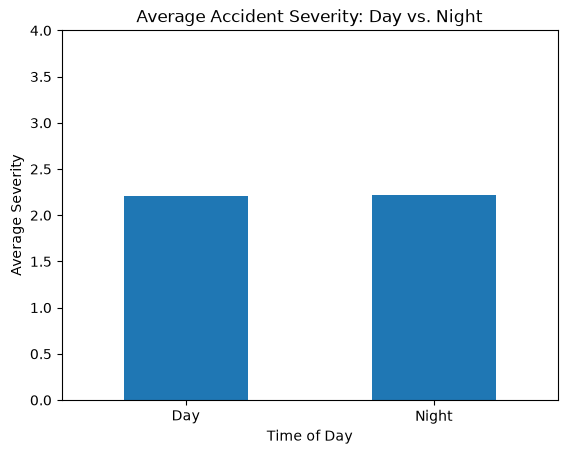

In [11]:
import matplotlib.pyplot as plt

avg_severity = df_clean.groupby("Sunrise_Sunset")["Severity"].mean()

avg_severity.plot(kind="bar")

plt.title("Average Accident Severity: Day vs. Night")
plt.xlabel("Time of Day")
plt.ylabel("Average Severity")
plt.xticks(rotation=0) 
plt.ylim(0,4)

plt.show()